In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import matplotlib.figure
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from matplotlib.colors import Colormap, ListedColormap
import matplotlib.pyplot as plt
import scienceplots
from plot_network import sciplot_style
from typing import Optional

In [3]:
from math import log
def plot_metric(raw_df: pd.DataFrame, ylabel: str, methods_list: list, scale: Optional[str], figsize=(10, 5)):
    """Plot metric for each graphon using sciplot_style in log scale

    Parameters
    ----------
    raw_df : pandas.DataFrame
        Dataframe with the results of the experiments
    ylabel : str
        Metric to plot
    methods_list : list
        List of methods to plot
    scale : str
        Scale of the x and y axis
    figsize : tuple, optional
        figsize, by default (10, 5)
    """
    if ylabel == 'MSE':
        idx = 3
    elif ylabel == 'MAE':
        idx = 5
    elif ylabel == 'AUC':
        idx = 7
    else:
        idx = 9
    pparam = dict(xlabel='n', ylabel=ylabel)
    # Iterate over each graphons, plot results from all methods for each graphon
    for graphon in raw_df[raw_df.columns[1]].unique():
        df = raw_df[raw_df[raw_df.columns[1]] == graphon]
        #extract the n list
        x = df['n'].unique()
        y = []
        p = []
        for method in methods_list:
            #print(df[df[raw_df.columns[0]] == method][raw_df.columns[idx]])
            if scale == "log":
                y.append(np.log(df[df[raw_df.columns[0]] == method][raw_df.columns[idx]])) # MSE is 3rd column
            else:
                y.append(df[df[raw_df.columns[0]] == method][raw_df.columns[idx]])
            p.append(method)
        if scale == "log":
            fig, ax = sciplot_style(x = np.log(x), y= y, p = p, llegend= llegend, pparam= pparam)
        else:
            fig, ax = sciplot_style(x = x, y= y, p = p, llegend= llegend, pparam= pparam)
        #change figsize
        fig.set_size_inches(figsize)
        #title
        ax.set_title(str(graphon))
        ax.legend()
        plt.show()

# Raw plots

## Plot on unsparsified data

In [4]:
# import data from relative path
raw_df = pd.read_csv('results/usual_graphon/first_run.csv')
raw_df.head()
headers_as_string = ", ".join(raw_df.columns)
print(raw_df.columns[1])

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = raw_df[raw_df.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic", "HistogramEstimator", "SAS", "USVT", "NBDsmooth", "Completion"]

llegend = dict(title='Methods')
print(methods_list)

Type of Graphon
['SmoothNetHist_bic', 'HistogramEstimator', 'SAS', 'USVT', 'NBDsmooth', 'Completion']


### MSE plots

In [ ]:
plot_metric(raw_df, 'MSE', methods_list, scale="log", figsize=(6, 6))

### MAE plots

In [ ]:
plot_metric(raw_df, 'MAE', methods_list, figsize=(10, 6))

### AUC plots

In [ ]:
plot_metric(raw_df, 'AUC', methods_list, figsize=(10, 6))

### AUPRC plots

In [ ]:
plot_metric(raw_df, 'AUPRC', methods_list, figsize=(10, 6))

## Plot on data sparsified by 1/3

In [5]:
# import data from relative path
raw_df_sparse = pd.read_csv('results/usual_graphon/run_scale_1div3.csv')
raw_df_sparse.head()
headers_as_string = ", ".join(raw_df_sparse.columns)

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = raw_df_sparse[raw_df_sparse.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic", "HistogramEstimator", "SAS", "USVT", "NBDsmooth", "Completion"]

llegend = dict(title='Methods')

### MSE

In [ ]:
plot_metric(raw_df, 'MSE', methods_list, scale="log", figsize=(6, 6))

### MAE

In [ ]:
plot_metric(raw_df_sparse, 'MAE', figsize=(10, 6), methods_list)

### AUC

In [ ]:
plot_metric(raw_df_sparse, 'AUC', figsize=(10, 6), methods_list)

### AUPRC

In [ ]:
plot_metric(raw_df_sparse, 'AUPRC', figsize=(10, 6), methods_list)

## Plot on data sparsified by 1/6

In [6]:
# import data from relative path
raw_df_sparse = pd.read_csv('results/usual_graphon/run_scale_1div6.csv')
raw_df_sparse.head()
headers_as_string = ", ".join(raw_df_sparse.columns)

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = raw_df_sparse[raw_df_sparse.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic", "HistogramEstimator", "SAS", "USVT", "NBDsmooth", "Completion"]

llegend = dict(title='Methods')

### MSE

In [ ]:
plot_metric(raw_df, 'MSE', methods_list, scale="log", figsize=(6, 6))

### MAE

In [ ]:
plot_metric(raw_df_sparse, 'MAE', figsize=(10, 6), methods_list)

### AUC

In [ ]:
plot_metric(raw_df_sparse, 'AUC', figsize=(10, 6), methods_list)

### AUPRC

In [ ]:
plot_metric(raw_df_sparse, 'AUPRC', figsize=(10, 6), methods_list)

# Cherry picking

## With sparse factor 1

In [7]:
# import data from relative path
df_cherry_comp_1 = pd.read_csv('results/usual_graphon/cherrypick_1_complete.csv')
df_cherry_comp_1.head()
headers_as_string = ", ".join(df_cherry_comp_1.columns)
print(df_cherry_comp_1.columns[13])
print(df_cherry_comp_1.columns[14])

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = df_cherry_comp_1[df_cherry_comp_1.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic", "SAS", "USVT"]#, "NBDsmooth", "Completion"]

llegend = dict(title='Methods')
print(methods_list)
# crop raw df to get only method_list
df_cherry_comp_1 = df_cherry_comp_1[df_cherry_comp_1[df_cherry_comp_1.columns[0]].isin(methods_list)]
# Correct mistake in the type of graphon for method HistogramEstimator
# Replace all type of graphon for HistogramEstimator lines by previous type of graphon associated to row of SmoothNetHist_bic
for _ in range(20):
    df_cherry_comp_1.loc[df_cherry_comp_1[df_cherry_comp_1.columns[0]] == 'HistogramEstimator', df_cherry_comp_1.columns[1]] = df_cherry_comp_1[df_cherry_comp_1.columns[1]].shift(1)

RatioPar
std(RatioPar)
['SmoothNetHist_bic', 'SAS', 'USVT']


In [ ]:
plot_metric(df_cherry_comp_1, 'MSE', methods_list, scale = "log", figsize=(5, 5))

In [ ]:
plot_metric(df_cherry_comp_1, 'AUC', methods_list, scale=None, figsize=(5, 5))

In [ ]:
plot_metric(df_cherry_comp_1, 'AUPRC', methods_list, scale = None, figsize=(5, 5))

In [ ]:
#new data set with fewer blocks
df_cherry_comp_1_smaller_block = pd.read_csv('results/usual_graphon/cherrypick_sbm_smaller_block.csv')
df_cherry_comp_1_smaller_block.head()
headers_as_string = ", ".join(df_cherry_comp_1_smaller_block.columns)
print(df_cherry_comp_1_smaller_block.columns[1])

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = df_cherry_comp_1_smaller_block[df_cherry_comp_1_smaller_block.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic", "SAS", "USVT"]

llegend = dict(title='Methods')
print(methods_list)

df_cherry_comp_1_smaller_block = df_cherry_comp_1_smaller_block[df_cherry_comp_1_smaller_block[df_cherry_comp_1_smaller_block.columns[0]].isin(methods_list)]

In [ ]:
plot_metric(df_cherry_comp_1_smaller_block, 'MSE', methods_list, scale = "log", figsize=(5, 5))

In [ ]:
plot_metric(df_cherry_comp_1_smaller_block, 'AUC', methods_list, scale=None, figsize=(5, 5))

## With sparse factor 1/3

In [8]:
# import data from relative path
df_cherry_comp_1div3 = pd.read_csv('results/usual_graphon/cherrypick_1div3_complete.csv')
df_cherry_comp_1div3.head()
headers_as_string = ", ".join(df_cherry_comp_1div3.columns)
print(df_cherry_comp_1div3.columns[1])

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = df_cherry_comp_1div3[df_cherry_comp_1div3.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic", "SAS", "USVT"]#, "NBDsmooth", "Completion"]

llegend = dict(title='Methods')
print(methods_list)
# crop raw df to get only method_list
df_cherry_comp_1div3 = df_cherry_comp_1div3[df_cherry_comp_1div3[df_cherry_comp_1div3.columns[0]].isin(methods_list)]
# Correct mistake in the type of graphon for method HistogramEstimator
# Replace all type of graphon for HistogramEstimator lines by previous type of graphon associated to row of SmoothNetHist_bic
for _ in range(20):
    df_cherry_comp_1div3.loc[df_cherry_comp_1div3[df_cherry_comp_1div3.columns[0]] == 'HistogramEstimator', df_cherry_comp_1div3.columns[1]] = df_cherry_comp_1div3[df_cherry_comp_1div3.columns[1]].shift(1)

Type of Graphon
['SmoothNetHist_bic', 'SAS', 'USVT']


In [ ]:
plot_metric(df_cherry_comp_1div3, 'MSE', methods_list, scale = "log", figsize=(5, 5))

In [ ]:
plot_metric(df_cherry_comp_1div3, 'AUC', methods_list, scale=None, figsize=(5, 5))

## With sparse factor 1/6

In [32]:
# import data from relative path
df_cherry_comp_1div6 = pd.read_csv('results/usual_graphon/cherrypick_1div6_complete.csv')
df_cherry_comp_1div6.head()
headers_as_string = ", ".join(df_cherry_comp_1div6.columns)
print(df_cherry_comp_1div6.columns[1])

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = df_cherry_comp_1div6[df_cherry_comp_1div6.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic", "SAS", "USVT"]#, "NBDsmooth", "Completion"]

llegend = dict(title='Methods')
print(methods_list)
# crop raw df to get only method_list
df_cherry_comp_1div6 = df_cherry_comp_1div6[df_cherry_comp_1div6[df_cherry_comp_1div6.columns[0]].isin(methods_list)]
# Correct mistake in the type of graphon for method HistogramEstimator
# Replace all type of graphon for HistogramEstimator lines by previous type of graphon associated to row of SmoothNetHist_bic
for _ in range(20):
    df_cherry_comp_1div6.loc[df_cherry_comp_1div6[df_cherry_comp_1div6.columns[0]] == 'HistogramEstimator', df_cherry_comp_1div6.columns[1]] = df_cherry_comp_1div6[df_cherry_comp_1div6.columns[1]].shift(1)

Type of Graphon
['SmoothNetHist_bic', 'SAS', 'USVT']


In [ ]:
plot_metric(df_cherry_comp_1div6, 'MSE', methods_list, scale = "log", figsize=(5, 5))

In [ ]:
plot_metric(df_cherry_comp_1div6, 'AUC', methods_list, scale=None, figsize=(5, 5))

# Plot selection

In [232]:
# select the data from each df corresponding to the type of graphon you are picking
graphon_type_df_1 = ["|x - y|", "assortative_sbm", "dissassortative_sbm"]
graphon_type_df_1div6 = []#["sinusoidal"]

#extract from df_cherry_comp_1 the data corresponding to the type of graphon you are picking
df_cherry_comp_1_plot = df_cherry_comp_1[df_cherry_comp_1[df_cherry_comp_1.columns[1]].isin(graphon_type_df_1)]

#extract from df_cherry_comp_1div6 the data corresponding to the type of graphon you are picking
df_cherry_comp_1div6_plot = df_cherry_comp_1div6[df_cherry_comp_1div6[df_cherry_comp_1div6.columns[1]].isin(graphon_type_df_1div6)]

In [134]:
#import common graphons
from pygraphon.graphons import common_graphons
n = 500

from palettable.colorbrewer.sequential import YlOrRd_9
colors = YlOrRd_9.mpl_colors
hex_colors = YlOrRd_9.hex_colors

llegend = dict(title='Methods')

In [233]:
methods_list = ["SmoothNetHist_bic", "SAS", "USVT"]

In [238]:
def plot_graphon(raw_df, graphon, metric, methods_list, scale):
    if metric == 'MSE':
        idx = 3
    elif metric == 'MAE':
        idx = 5
    elif metric == 'AUC':
        idx = 7
    else:
        idx = 9
    df = raw_df[raw_df[raw_df.columns[1]] == graphon]
    #extract the n list
    x = df['n'].unique()
    y = []
    for method in methods_list:
        #print(df[df[raw_df.columns[0]] == method][raw_df.columns[idx]])
        if scale == "log":
            y.append(np.log(df[df[raw_df.columns[0]] == method][raw_df.columns[idx]])) # MSE is 3rd column
        else:
            y.append(df[df[raw_df.columns[0]] == method][raw_df.columns[idx]])
    return x, y

In [125]:
methods_list

['SmoothNetHist_bic', 'SAS', 'USVT']

In [ ]:
from pygraphon.plots.plots_graphon import _add_colorbar
j=0
n=500
font = {'size'   : 22}

matplotlib.rc('font', **font)
n_graphons = len(graphon_type_df_1+graphon_type_df_1div6)
fig, ax = plt.subplots(n_graphons, 3, figsize=(25, 15), sharex="col")
fig.subplots_adjust(hspace=0.3, wspace=0.3)
xticks = [0, n - 1]
yticks = [0, n - 1]
for graphon in graphon_type_df_1+graphon_type_df_1div6:
    print(graphon)
    if graphon == "|x - y|":
        g = common_graphons["latent_distance"]
    elif graphon =="1/(1 + exp(-10(x^2 + y^2)))":
        g = common_graphons["logit_sum"]
    elif graphon =="log(1 + 0.5*max(x,y))":
        g = common_graphons["log_1_p"]
    else:
        g = common_graphons[graphon]
    im = ax[j,0].imshow(np.rot90(g.get_edge_probabilities(n,False,True)), cmap=plt.cm.binary, vmin=0, vmax=1)
    #_add_colorbar(im, ax = ax[j,0])

    ax[j,0].set_xticks(xticks)
    ax[j,0].set_yticks(yticks)

    ax[j,0].set_xticklabels(['0',  '1'])
    ax[j,0].set_yticklabels(['1', '0'])
    
    if graphon == "sinusoidal":
        x,y  = plot_graphon_rp(df_cherry_rp_1div6_plot, graphon, 2)
        _,y_std  = plot_graphon_rp(df_cherry_rp_1div6_plot, graphon, 3)
    else:
        x,y  = plot_graphon_rp(df_cherry_rp_1_plot, graphon, 2)
        _,y_std  = plot_graphon_rp(df_cherry_rp_1_plot, graphon, 3)
    with plt.style.context("science"):
        plt.rc(
            "text", usetex=False
        )
        ax[j,1].plot(x, y, linewidth=1, marker = 'o')
        ax[j,1].fill_between(x, y - y_std, y + y_std, color='blue', alpha=0.2, label='Standard Deviation')
        ax[j,2].plot(x, ratio_auc[20*j:20*(j+1)], linewidth=1, marker = 'o')
        y_lim_lower = 0.99
        y_lim_upper = 1.0001
        #ax[j,2].set_ylim([y_lim_lower, y_lim_upper])
        #ax[j,2].set_yticks([y_lim_lower, 1])
        ax[j,1].set_ylim(bottom=0)

    j+=1
ax[0,1].set_title("Ratio num. parameters")
ax[0,2].set_title("Ratio AUC")
ax[0,0].set_title("Graphons")
ax[-1,1].set_xlabel("n")
ax[-1,2].set_xlabel("n")
plt.show()

In [237]:
methods_list

['SmoothNetHist_bic', 'SAS', 'USVT']

findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not

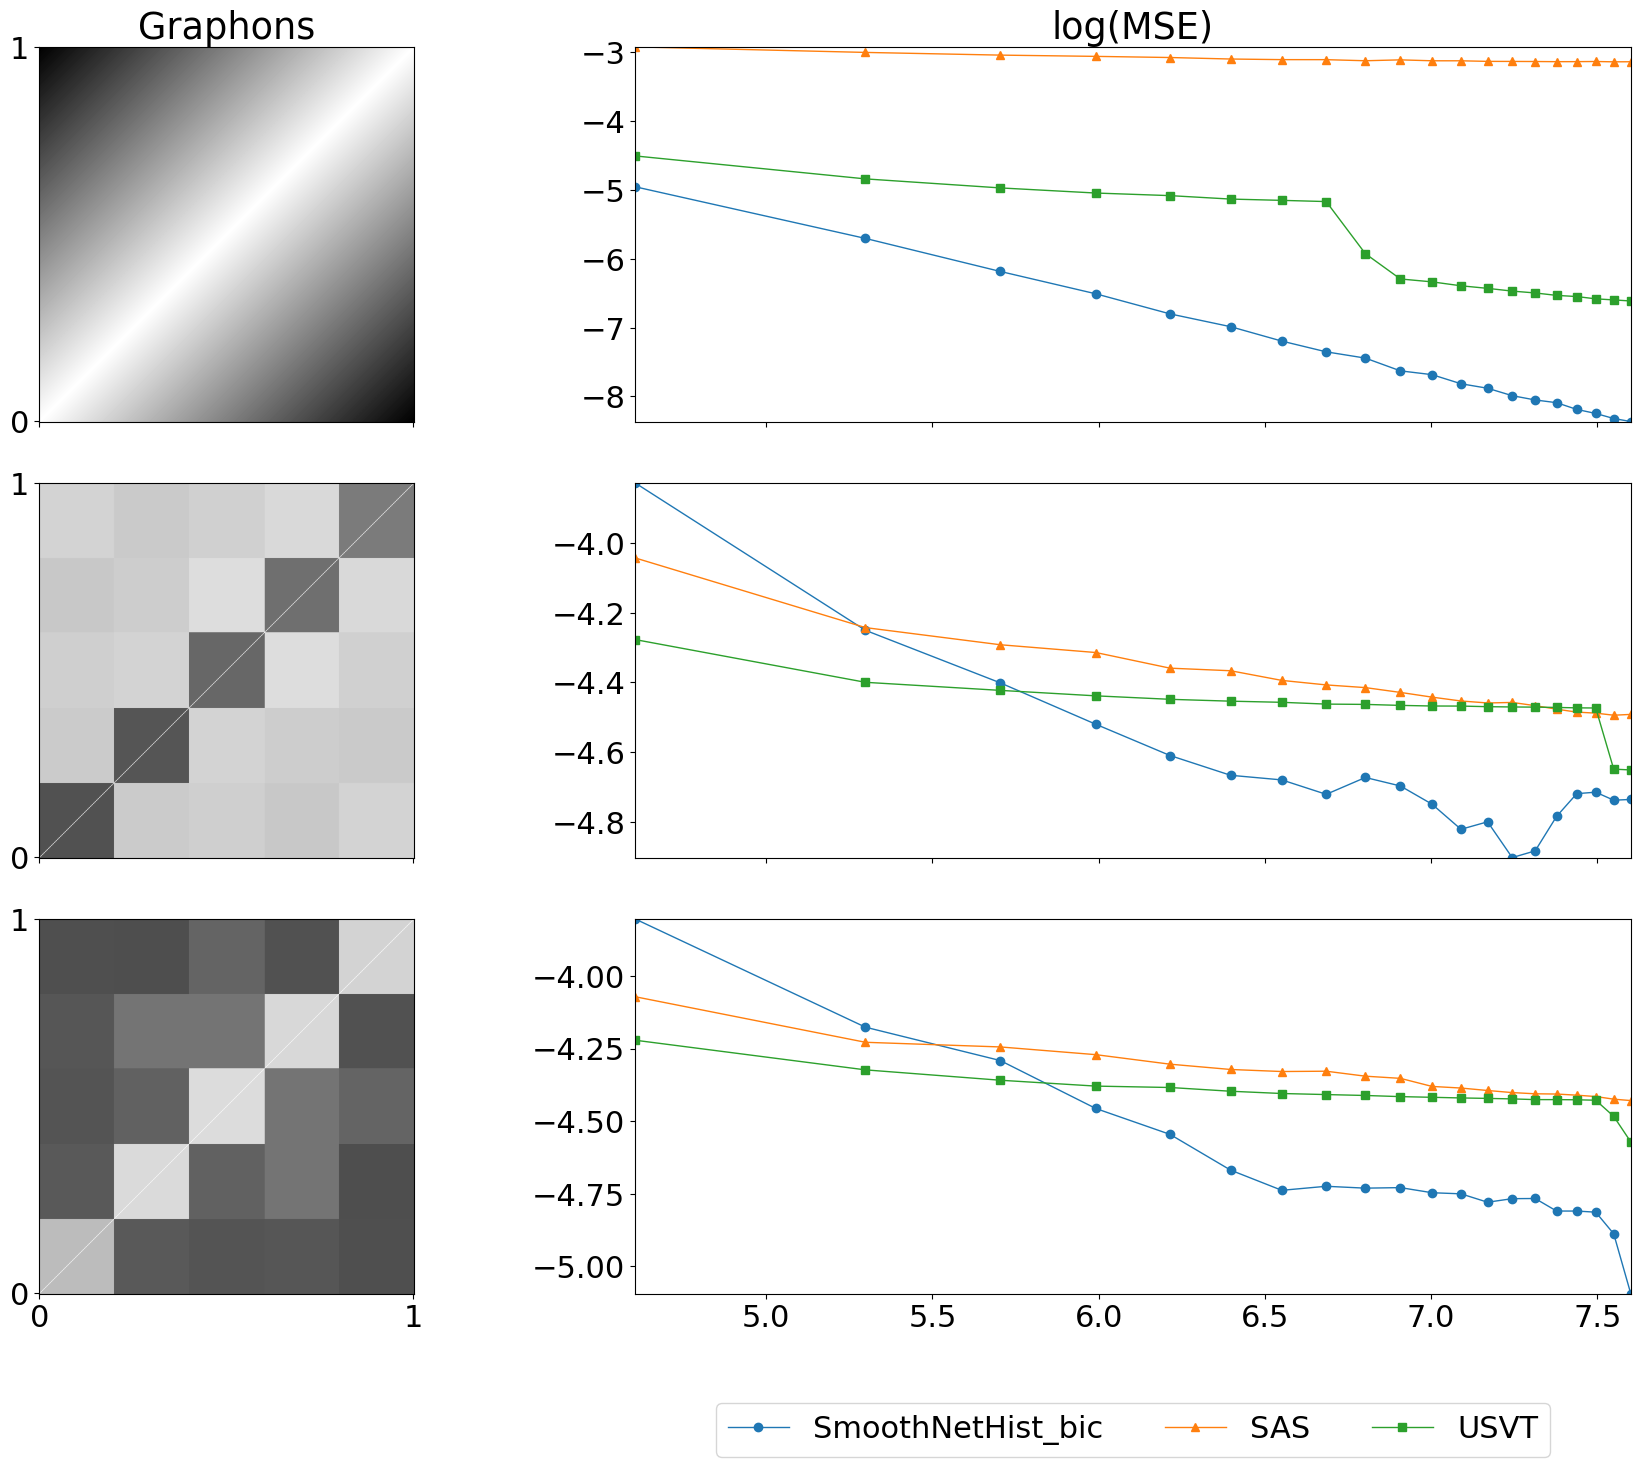

In [246]:
from pygraphon.plots.plots_graphon import _add_colorbar
j=0
n_graphons = len(graphon_type_df_1+graphon_type_df_1div6)
fig, ax = plt.subplots(n_graphons, 2, figsize=(20, 15), sharex="col")
fig.subplots_adjust(hspace=0.3, wspace=0.01)
xticks = [0, n - 1]
yticks = [0, n - 1]
markers = ['o', '^', 's']
for graphon in graphon_type_df_1+graphon_type_df_1div6:
    if graphon == "|x - y|":
        g = common_graphons["latent_distance"]
    else:
        g = common_graphons[graphon]
    im = ax[j,0].imshow(np.rot90(g.get_edge_probabilities(n,False,True)), cmap=plt.cm.binary, vmin=0, vmax=1)
    #_add_colorbar(im, ax = ax[j,0])

    ax[j,0].set_xticks(xticks)
    ax[j,0].set_yticks(yticks)

    ax[j,0].set_xticklabels(['0', '1'])
    ax[j,0].set_yticklabels(['1', '0'])
    
    #pparam = dict(xlabel='log(n)', ylabel="log(MSE)")
    #pparam2 = dict(xlabel='n', ylabel="AUC")
    if graphon == "sinusoidal":
        x,y  = plot_graphon(df_cherry_comp_1div6_plot, graphon, 'MSE', methods_list, scale = "log")
        x_auc,y_auc  = plot_graphon(df_cherry_comp_1div6_plot, graphon, 'AUC', methods_list, scale = None)
    else:
        x,y  = plot_graphon(df_cherry_comp_1_plot, graphon, 'MSE', methods_list, scale = "log")
        x_auc,y_auc  = plot_graphon(df_cherry_comp_1_plot, graphon, 'AUC', methods_list, scale = None)
    p= methods_list
    with plt.style.context("science"):
        plt.rc(
            "text", usetex=False
        )  # to get around the RuntimeError: LaTeX was not able to process the following string:
        for i, val in enumerate(y):
            if p is None:
                ax[j,1].plot(np.log(x), val, label="Order {}".format(i + 1))
                #ax[j,2].plot(x_auc, y_auc[i], label="Order {}".format(i + 1))
            else:
                ax[j,1].plot(np.log(x), val, label=p[i], linewidth=1, marker = markers[i])
                #ax[j,2].plot(x_auc, y_auc[i], label=p[i], linewidth=1, marker = markers[i])
        #if llegend is not None:
            #ax[j,1].set(**pparam)
            #ax[j,2].legend(**llegend)
            #ax[j,2].set(**pparam2)
        ax[j,1].autoscale(tight=True)
    j+=1
ax[-1,1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.25),
          fancybox=True, shadow=False, ncol=3)
ax[0,1].set_title("log(MSE)")
ax[0,0].set_title("Graphons")
plt.tight_layout()
plt.show()

# RatioPar

In [141]:
performance = False
if performance:
    graphon_type_df_1 = ["|x - y|", "assortative_sbm", "dissassortative_sbm", "partition"]
    graphon_type_df_1div6 = ["sinusoidal"]
else:
    graphon_type_df_1 = ["1/(1 + exp(-10(x^2 + y^2)))", "log(1 + 0.5*max(x,y))", "hsbm", "hsbm_partition"]
    graphon_type_df_1div6 = ["sinusoidal"]


In [142]:
# import data from relative path
df_cherry_comp_1 = pd.read_csv('results/usual_graphon/cherrypick_1_complete.csv')
df_cherry_comp_1.head()
headers_as_string = ", ".join(df_cherry_comp_1.columns)
print(df_cherry_comp_1.columns[13])
print(df_cherry_comp_1.columns[14])

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = df_cherry_comp_1[df_cherry_comp_1.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic"]#, "SAS", "USVT"]#, "NBDsmooth", "Completion"]

# crop raw df to get only method_list
df_cherry_rp_1 = df_cherry_comp_1[df_cherry_comp_1[df_cherry_comp_1.columns[0]].isin(methods_list)][["Type of Graphon", "n", "RatioPar", "std(RatioPar)"]]
df_cherry_hist_1 = df_cherry_comp_1[df_cherry_comp_1[df_cherry_comp_1.columns[0]] == "HistogramEstimator"][["Type of Graphon", "n", "RatioPar", "std(RatioPar)"]]

RatioPar
std(RatioPar)


In [143]:
# import data from relative path
df_cherry_comp_1div6 = pd.read_csv('results/usual_graphon/cherrypick_1_complete.csv')
df_cherry_comp_1div6.head()
headers_as_string = ", ".join(df_cherry_comp_1div6.columns)
print(df_cherry_comp_1div6.columns[13])
print(df_cherry_comp_1div6.columns[14])

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = df_cherry_comp_1div6[df_cherry_comp_1div6.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic"]#, "SAS", "USVT"]#, "NBDsmooth", "Completion"]

# crop raw df to get only method_list
df_cherry_rp_1div6 = df_cherry_comp_1div6[df_cherry_comp_1div6[df_cherry_comp_1div6.columns[0]].isin(methods_list)][["Type of Graphon", "n", "RatioPar", "std(RatioPar)"]]

RatioPar
std(RatioPar)


In [144]:
#extract from df_cherry_comp_1 the data corresponding to the type of graphon you are picking
df_cherry_rp_1_plot = df_cherry_rp_1[df_cherry_rp_1[df_cherry_rp_1.columns[0]].isin(graphon_type_df_1)]
df_cherry_rp_1div6_plot = df_cherry_rp_1div6[df_cherry_rp_1div6[df_cherry_rp_1div6.columns[0]].isin(graphon_type_df_1div6)]


In [145]:
def plot_graphon_rp(raw_df, graphon, idx):
    df = raw_df[raw_df[raw_df.columns[0]] == graphon]
    x = df['n'].unique()
    y = df[raw_df.columns[idx]]
    return x, y

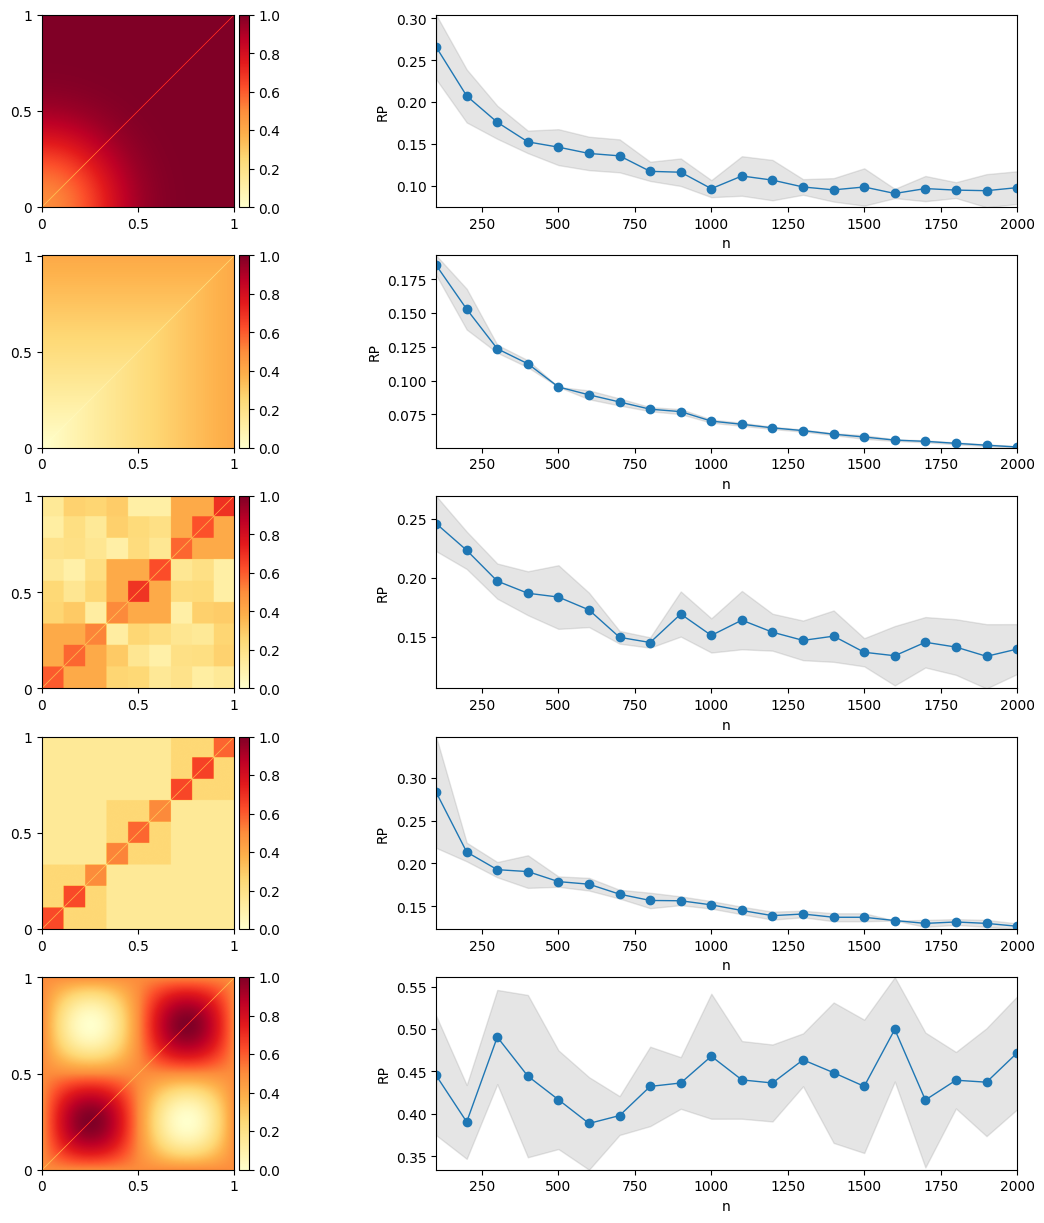

In [148]:
from pygraphon.plots.plots_graphon import _add_colorbar
j=0
n=500
n_graphons = len(graphon_type_df_1+graphon_type_df_1div6)
fig, ax = plt.subplots(n_graphons, 2, figsize=(15, 15))
fig.subplots_adjust(hspace=0.25, wspace=0.001)
xticks = [0, n/ 2, n - 1]
yticks = [0, n/ 2, n - 1]
for graphon in graphon_type_df_1+graphon_type_df_1div6:
    if graphon == "|x - y|":
        g = common_graphons["latent_distance"]
    elif graphon == "1/(1 + exp(-10(x^2 + y^2)))":
        g = common_graphons["logit_sum"]
    elif graphon == "log(1 + 0.5*max(x,y))":
        g = common_graphons["log_1_p"]
    else:
        g = common_graphons[graphon]
    im = ax[j,0].imshow(np.rot90(g.get_edge_probabilities(n,False,True)), cmap=YlOrRd_9.mpl_colormap, vmin=0, vmax=1)
    _add_colorbar(im, ax = ax[j,0])

    ax[j,0].set_xticks(xticks)
    ax[j,0].set_yticks(yticks)

    ax[j,0].set_xticklabels(['0', '0.5', '1'])
    ax[j,0].set_yticklabels(['1', '0.5', '0'])
    
    pparam = dict(xlabel='n', ylabel="RP")
    if graphon == "sinusoidal":
        x,y  = plot_graphon_rp(df_cherry_rp_1div6_plot, graphon, 2)
        _,y_std  = plot_graphon_rp(df_cherry_rp_1div6_plot, graphon, 3)
    else:
        x,y  = plot_graphon_rp(df_cherry_rp_1_plot, graphon, 2)
        _,y_std  = plot_graphon_rp(df_cherry_rp_1_plot, graphon, 3)
    with plt.style.context("science"):
        plt.rc(
            "text", usetex=False
        )
        ax[j,1].plot(x, y, linewidth=1, marker = 'o')
        ax[j,1].fill_between(x, y - y_std, y + y_std, color='gray', alpha=0.2, label='Standard Deviation')

        if llegend is not None:
            ax[j,1].set(**pparam)
        ax[j,1].autoscale(tight=True)
    j+=1

plt.show()

# Error ratio

In [149]:
performance = False
if performance:
    graphon_type_df_1 = ["|x - y|", "assortative_sbm", "dissassortative_sbm", "partition"]
    graphon_type_df_1div6 = ["sinusoidal"]
else:
    graphon_type_df_1 = ["1/(1 + exp(-10(x^2 + y^2)))", "log(1 + 0.5*max(x,y))", "hsbm_partition"]
    graphon_type_df_1div6 = []


In [150]:
# import data from relative path
df_cherry_comp_1 = pd.read_csv('results/usual_graphon/cherrypick_1_complete.csv')
df_cherry_comp_1.head()
headers_as_string = ", ".join(df_cherry_comp_1.columns)

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = df_cherry_comp_1[df_cherry_comp_1.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic", "HistogramEstimator"]

# crop raw df to get only method_list
df_cherry_hist_1 = df_cherry_comp_1[df_cherry_comp_1[df_cherry_comp_1.columns[0]].isin(methods_list)][["Method", "Type of Graphon", "n", "MSE", "AUC"]]
for _ in range(20):
    df_cherry_hist_1.loc[df_cherry_hist_1[df_cherry_hist_1.columns[0]] == 'HistogramEstimator', df_cherry_hist_1.columns[1]] = df_cherry_hist_1[df_cherry_hist_1.columns[1]].shift(1)
df_cherry_hist_1.head()

,Method,Type of Graphon,n,MSE,AUC
0,SmoothNetHist_bic,sinusoidal,100,0.039776,0.781133
6,SmoothNetHist_bic,sinusoidal,200,0.035985,0.780916
12,SmoothNetHist_bic,sinusoidal,300,0.036471,0.781880
18,SmoothNetHist_bic,sinusoidal,400,0.035984,0.782984
24,SmoothNetHist_bic,sinusoidal,500,0.036302,0.783274


In [151]:
# import data from relative path
df_cherry_comp_1div6 = pd.read_csv('results/usual_graphon/cherrypick_1_complete.csv')
df_cherry_comp_1div6.head()
headers_as_string = ", ".join(df_cherry_comp_1div6.columns)

all_smoothNetHist_criterion = False
if all_smoothNetHist_criterion:
    methods_list = df_cherry_comp_1div6[df_cherry_comp_1div6.columns[0]].unique()
else:
    methods_list = ["SmoothNetHist_bic", "HistogramEstimator"]

# crop raw df to get only method_list
df_cherry_hist_1div6 = df_cherry_comp_1div6[df_cherry_comp_1div6[df_cherry_comp_1div6.columns[0]].isin(methods_list)][["Method", "Type of Graphon", "n", "MSE", "AUC"]]
df_cherry_hist_1div6.head()
for _ in range(20):
    df_cherry_hist_1div6.loc[df_cherry_hist_1div6[df_cherry_hist_1div6.columns[0]] == 'HistogramEstimator', df_cherry_hist_1div6.columns[1]] = df_cherry_hist_1div6[df_cherry_hist_1div6.columns[1]].shift(1)
df_cherry_hist_1div6.head()

,Method,Type of Graphon,n,MSE,AUC
0,SmoothNetHist_bic,sinusoidal,100,0.039776,0.781133
6,SmoothNetHist_bic,sinusoidal,200,0.035985,0.780916
12,SmoothNetHist_bic,sinusoidal,300,0.036471,0.781880
18,SmoothNetHist_bic,sinusoidal,400,0.035984,0.782984
24,SmoothNetHist_bic,sinusoidal,500,0.036302,0.783274


In [152]:
#extract from df_cherry_comp_1 the data corresponding to the type of graphon you are picking
df_cherry_hist_1_plot = df_cherry_hist_1[df_cherry_hist_1[df_cherry_hist_1.columns[1]].isin(graphon_type_df_1)]
df_cherry_hist_1div6_plot = df_cherry_hist_1div6[df_cherry_hist_1div6[df_cherry_hist_1div6.columns[1]].isin(graphon_type_df_1div6)]
df_cherry_hist_1_plot.head()

,Method,Type of Graphon,n,MSE,AUC
1100,SmoothNetHist_bic,hsbm_partition,100,0.019362,0.660452
1106,SmoothNetHist_bic,hsbm_partition,200,0.011019,0.648712
1112,SmoothNetHist_bic,hsbm_partition,300,0.010399,0.651480
1118,SmoothNetHist_bic,hsbm_partition,400,0.008565,0.644159
1124,SmoothNetHist_bic,hsbm_partition,500,0.007868,0.639192


In [153]:
#get the ratio of corresponding MSE between SmoothNetHist_bic and HistogramEstimator when n is the same and graphon is the same
ratio_mse = []
n_list = df_cherry_hist_1_plot['n'].unique()
for graphon in graphon_type_df_1+graphon_type_df_1div6:
    for n in n_list:
        if graphon in graphon_type_df_1:
            ratio_mse.append(df_cherry_hist_1_plot[(df_cherry_hist_1_plot['n'] == n) & (df_cherry_hist_1_plot['Type of Graphon'] == graphon) & (df_cherry_hist_1_plot['Method'] == 'SmoothNetHist_bic')]['MSE'].values[0]
                             /df_cherry_hist_1_plot[(df_cherry_hist_1_plot['n'] == n) & (df_cherry_hist_1_plot['Type of Graphon'] == graphon) & (df_cherry_hist_1_plot['Method'] == 'HistogramEstimator')]['MSE'].values[0])
        else:
            ratio_mse.append(df_cherry_hist_1div6_plot[(df_cherry_hist_1div6_plot['n'] == n) & (df_cherry_hist_1div6_plot['Type of Graphon'] == graphon) & (df_cherry_hist_1div6_plot['Method'] == 'SmoothNetHist_bic')]['MSE'].values[0]
                             / df_cherry_hist_1div6_plot[(df_cherry_hist_1div6_plot['n'] == n) & (df_cherry_hist_1div6_plot['Type of Graphon'] == graphon) & (df_cherry_hist_1div6_plot['Method'] == 'HistogramEstimator')]['MSE'].values[0])

In [154]:
#do the same for auc
ratio_auc = []
n_list = df_cherry_hist_1_plot['n'].unique()
for graphon in graphon_type_df_1+graphon_type_df_1div6:
    print(graphon)
    for n in n_list:
        if graphon in graphon_type_df_1:
            ratio_auc.append(df_cherry_hist_1_plot[(df_cherry_hist_1_plot['n'] == n) & (df_cherry_hist_1_plot['Type of Graphon'] == graphon) & (df_cherry_hist_1_plot['Method'] == 'SmoothNetHist_bic')]['AUC'].values[0]
                             /df_cherry_hist_1_plot[(df_cherry_hist_1_plot['n'] == n) & (df_cherry_hist_1_plot['Type of Graphon'] == graphon) & (df_cherry_hist_1_plot['Method'] == 'HistogramEstimator')]['AUC'].values[0])
        else:
            ratio_auc.append(df_cherry_hist_1div6_plot[(df_cherry_hist_1div6_plot['n'] == n) & (df_cherry_hist_1div6_plot['Type of Graphon'] == graphon) & (df_cherry_hist_1div6_plot['Method'] == 'SmoothNetHist_bic')]['AUC'].values[0]
                             / df_cherry_hist_1div6_plot[(df_cherry_hist_1div6_plot['n'] == n) & (df_cherry_hist_1div6_plot['Type of Graphon'] == graphon) & (df_cherry_hist_1div6_plot['Method'] == 'HistogramEstimator')]['AUC'].values[0])

1/(1 + exp(-10(x^2 + y^2)))
log(1 + 0.5*max(x,y))
hsbm_partition


In [155]:
df_cherry_rp_1div6_plot.head()

,Type of Graphon,n,RatioPar,std(RatioPar)
0,sinusoidal,100,0.445238,0.070405
6,sinusoidal,200,0.390476,0.043513
12,sinusoidal,300,0.490476,0.055533
18,sinusoidal,400,0.444444,0.095646
24,sinusoidal,500,0.416667,0.058161


1/(1 + exp(-10(x^2 + y^2)))
log(1 + 0.5*max(x,y))


findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.


hsbm_partition


findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not

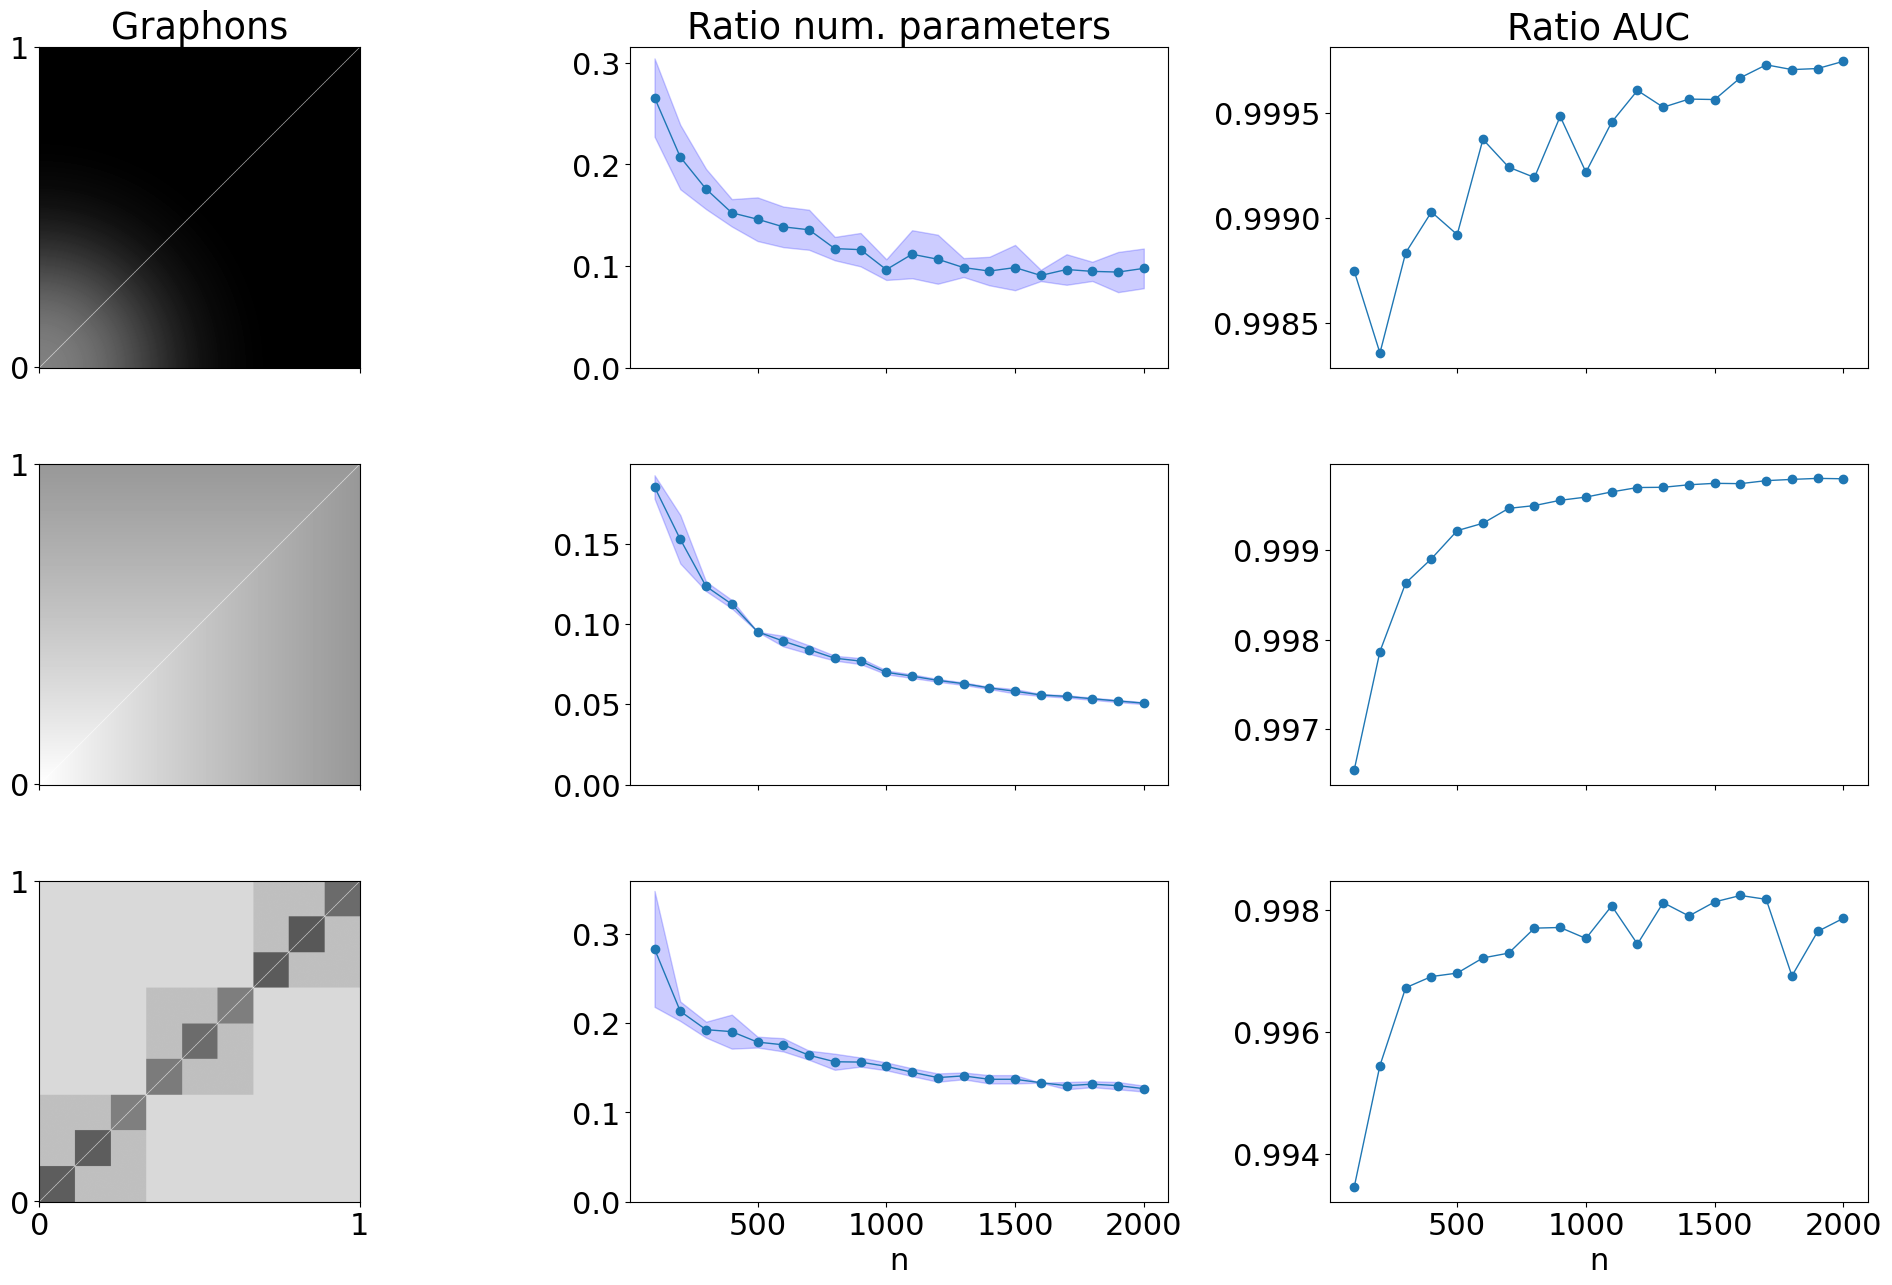

In [230]:
from pygraphon.plots.plots_graphon import _add_colorbar
j=0
n=500
font = {'size'   : 22}

matplotlib.rc('font', **font)
n_graphons = len(graphon_type_df_1+graphon_type_df_1div6)
fig, ax = plt.subplots(n_graphons, 3, figsize=(25, 15), sharex="col")
fig.subplots_adjust(hspace=0.3, wspace=0.3)
xticks = [0, n - 1]
yticks = [0, n - 1]
for graphon in graphon_type_df_1+graphon_type_df_1div6:
    print(graphon)
    if graphon == "|x - y|":
        g = common_graphons["latent_distance"]
    elif graphon =="1/(1 + exp(-10(x^2 + y^2)))":
        g = common_graphons["logit_sum"]
    elif graphon =="log(1 + 0.5*max(x,y))":
        g = common_graphons["log_1_p"]
    else:
        g = common_graphons[graphon]
    im = ax[j,0].imshow(np.rot90(g.get_edge_probabilities(n,False,True)), cmap=plt.cm.binary, vmin=0, vmax=1)
    #_add_colorbar(im, ax = ax[j,0])

    ax[j,0].set_xticks(xticks)
    ax[j,0].set_yticks(yticks)

    ax[j,0].set_xticklabels(['0',  '1'])
    ax[j,0].set_yticklabels(['1', '0'])
    
    if graphon == "sinusoidal":
        x,y  = plot_graphon_rp(df_cherry_rp_1div6_plot, graphon, 2)
        _,y_std  = plot_graphon_rp(df_cherry_rp_1div6_plot, graphon, 3)
    else:
        x,y  = plot_graphon_rp(df_cherry_rp_1_plot, graphon, 2)
        _,y_std  = plot_graphon_rp(df_cherry_rp_1_plot, graphon, 3)
    with plt.style.context("science"):
        plt.rc(
            "text", usetex=False
        )
        ax[j,1].plot(x, y, linewidth=1, marker = 'o')
        ax[j,1].fill_between(x, y - y_std, y + y_std, color='blue', alpha=0.2, label='Standard Deviation')
        ax[j,2].plot(x, ratio_auc[20*j:20*(j+1)], linewidth=1, marker = 'o')
        y_lim_lower = 0.99
        y_lim_upper = 1.0001
        #ax[j,2].set_ylim([y_lim_lower, y_lim_upper])
        #ax[j,2].set_yticks([y_lim_lower, 1])
        ax[j,1].set_ylim(bottom=0)

    j+=1
ax[0,1].set_title("Ratio num. parameters")
ax[0,2].set_title("Ratio AUC")
ax[0,0].set_title("Graphons")
ax[-1,1].set_xlabel("n")
ax[-1,2].set_xlabel("n")
plt.show()

1/(1 + exp(-10(x^2 + y^2)))
log(1 + 0.5*max(x,y))


findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.


hsbm_partition


findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not found.
findfont: Font family 'normal' not

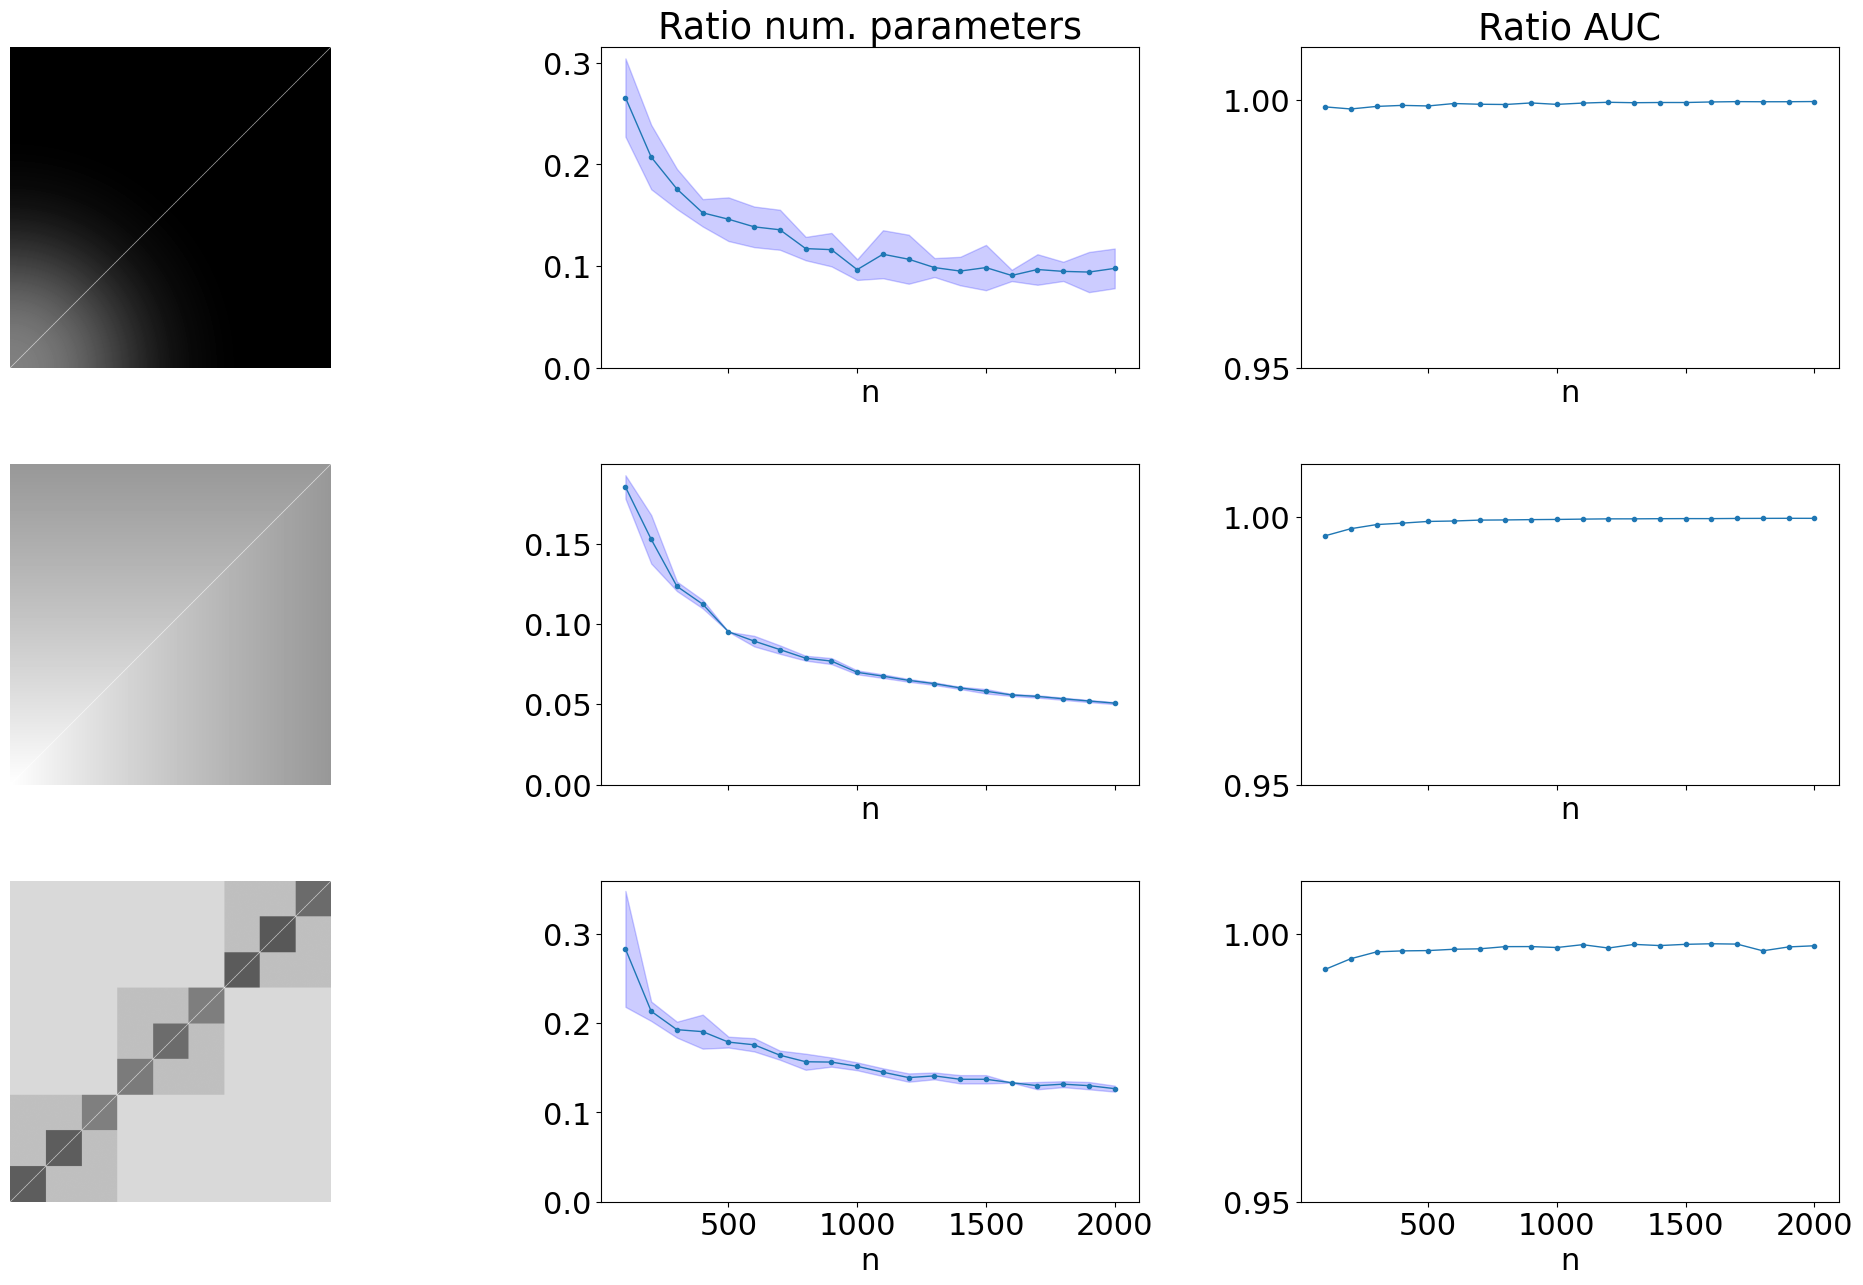

In [213]:
from pygraphon.plots.plots_graphon import _add_colorbar
from pygraphon.plots.utils import make_pretty

j=0
n=500
n_graphons = len(graphon_type_df_1+graphon_type_df_1div6)
fig, ax = plt.subplots(n_graphons, 3, figsize=(25, 15), sharex="col")
fig.subplots_adjust(hspace=0.3, wspace=0.3)
xticks = [0, n/ 2, n - 1]
yticks = [0, n/ 2, n - 1]
for graphon in graphon_type_df_1+graphon_type_df_1div6:
    print(graphon)
    if graphon == "|x - y|":
        g = common_graphons["latent_distance"]
    elif graphon =="1/(1 + exp(-10(x^2 + y^2)))":
        g = common_graphons["logit_sum"]
    elif graphon =="log(1 + 0.5*max(x,y))":
        g = common_graphons["log_1_p"]
    else:
        g = common_graphons[graphon]
    im = ax[j,0].imshow(np.rot90(g.get_edge_probabilities(n,False,True)), cmap=plt.cm.binary, vmin=0, vmax=1)
    #_add_colorbar(im, ax = ax[j,0])
    make_pretty(ax[j,0])
   

    #ax[j,0].set_xticklabels(['0', '0.5', '1'])
    #ax[j,0].set_yticklabels(['1', '0.5', '0'])
    
    pparam = dict(xlabel='n', ylabel=None)
    pparam2 = dict(xlabel='n', ylabel=None)
    if graphon == "sinusoidal":
        x,y  = plot_graphon_rp(df_cherry_rp_1div6_plot, graphon, 2)
        _,y_std  = plot_graphon_rp(df_cherry_rp_1div6_plot, graphon, 3)
    else:
        x,y  = plot_graphon_rp(df_cherry_rp_1_plot, graphon, 2)
        _,y_std  = plot_graphon_rp(df_cherry_rp_1_plot, graphon, 3)
    with plt.style.context("science"):
        plt.rc(
            "text", usetex=False
        )
        ax[j,1].plot(x, y, linewidth=1, marker = '.')
        ax[j,1].fill_between(x, y - y_std, y + y_std, color='blue', alpha=0.2, label='Standard Deviation')
        ax[j,2].plot(x, ratio_auc[20*j:20*(j+1)], linewidth=1, marker = '.')
        y_lim_lower = 0.95
        y_lim_upper = 1.01
        ax[j,2].set_ylim([y_lim_lower, y_lim_upper])
        ax[j,2].set_yticks([y_lim_lower, 1])
        ax[j,1].set_ylim(bottom=0)

        if llegend is not None:
            ax[j,1].set(**pparam)
            ax[j,2].set(**pparam2)
    
    j+=1
   
    ax[0,1].set_title("Ratio num. parameters")
    ax[0,2].set_title("Ratio AUC")
plt.show()

# Example of graphons

16


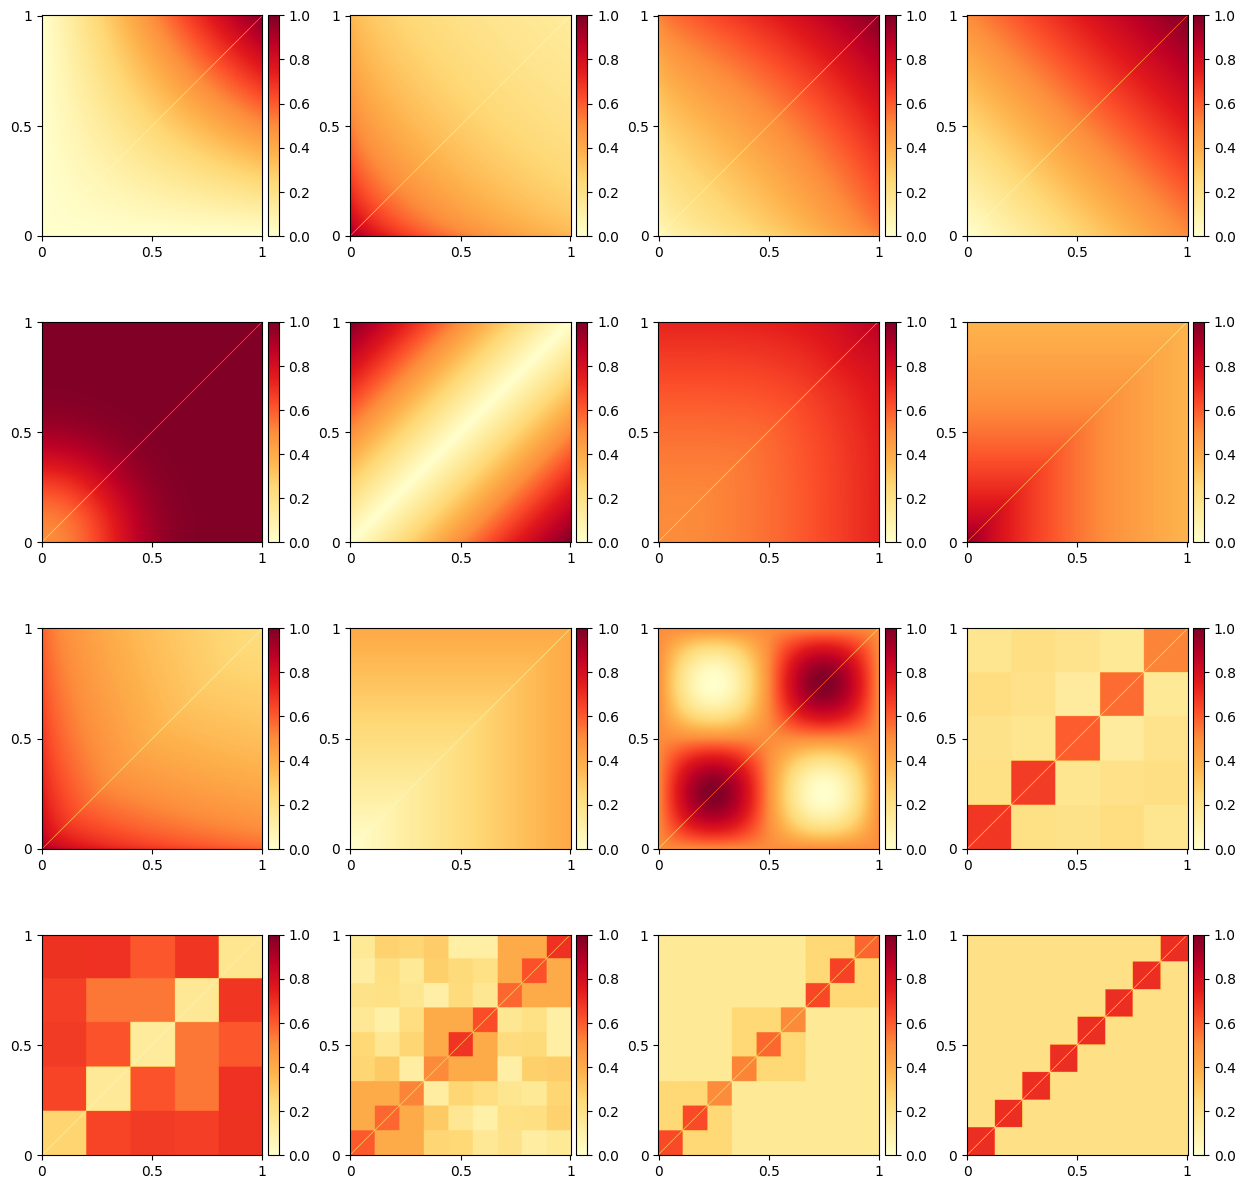

In [157]:
from pygraphon.graphons import common_graphons
from pygraphon.plots.plots_graphon import _add_colorbar
j=0
i=0
n=500
print(len(common_graphons))
fig, ax = plt.subplots(4, 4, figsize=(15, 15))
fig.subplots_adjust(hspace=0.3, wspace=0.3)
xticks = [0, n/ 2, n - 1]
yticks = [0, n/ 2, n - 1]
graphons = []
for g in common_graphons.keys():
    g = common_graphons[g]
    graphons.append(g)
for g in graphons:
    im = ax[i,j].imshow(np.rot90(g.get_edge_probabilities(n,False,True)), cmap=YlOrRd_9.mpl_colormap, vmin=0, vmax=1)
    _add_colorbar(im, ax = ax[j,0])

    ax[i,j].set_xticks(xticks)
    ax[i,j].set_yticks(yticks)

    ax[i,j].set_xticklabels(['0', '0.5', '1'])
    ax[i,j].set_yticklabels(['1', '0.5', '0'])
    j+=1
    if j == 4:
        j=0
        i+=1

plt.show()